# 02 — Feature-only learnability baselines

### How to read this notebook
Run cells top to bottom. Each Markdown cell states the question and expected result **before** the code. The printed and plotted numbers are measurements, not claims made in advance. The shared functions live in `src/experiment.py`. Open Jupyter from the project root so imports work.

## Question

Can each feature group be learned separately under the joint experiment's training settings? Use the same 1,024 examples (data seed 11), model seeds 42–46, width 32, full-batch plain SGD, learning rate 0.03, and 500 updates as the default run_all_experiments.py configuration. Both baselines use alpha=1, the joint reference scale. These are capability checks; input dimensions and parameter counts differ.

If you change the joint experiment settings, update these settings too.

In [1]:
from pathlib import Path
import os
import sys

# Resolve this experiment before imports and relative result paths.
ROOT = Path.cwd()
if not (ROOT / 'src' / 'experiment.py').is_file():
    ROOT = ROOT / 'experiment_1'
assert (ROOT / 'src' / 'experiment.py').is_file(), 'Start Jupyter in SimpBias or experiment_1.'
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.experiment import *
import torch
import numpy as np
import matplotlib.pyplot as plt
print('PyTorch:', torch.__version__)

PyTorch: 2.14.1+cpu


simple_only seed= 42 {'step': 500, 'accuracy': 1.0, 'loss': 0.01071010809391737}


complex_only seed= 42 {'step': 500, 'accuracy': 1.0, 'loss': 0.05370497331023216}
simple_only seed= 43 {'step': 500, 'accuracy': 1.0, 'loss': 0.010668640956282616}


complex_only seed= 43 {'step': 500, 'accuracy': 1.0, 'loss': 0.06187625974416733}
simple_only seed= 44 {'step': 500, 'accuracy': 1.0, 'loss': 0.011042356491088867}


complex_only seed= 44 {'step': 500, 'accuracy': 1.0, 'loss': 0.05515700951218605}


simple_only seed= 45 {'step': 500, 'accuracy': 1.0, 'loss': 0.01008453406393528}


complex_only seed= 45 {'step': 500, 'accuracy': 1.0, 'loss': 0.05028657615184784}


simple_only seed= 46 {'step': 500, 'accuracy': 1.0, 'loss': 0.010118457488715649}


complex_only seed= 46 {'step': 500, 'accuracy': 1.0, 'loss': 0.04646382853388786}
simple_only final accuracies: [1.0, 1.0, 1.0, 1.0, 1.0]
complex_only final accuracies: [1.0, 1.0, 1.0, 1.0, 1.0]


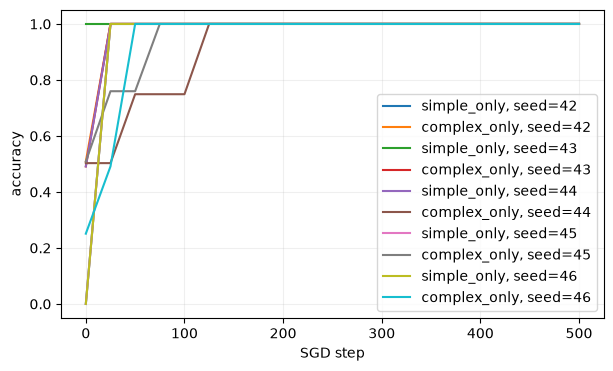

In [2]:
# Match the default joint-experiment configuration in run_all_experiments.py.
SEEDS = [42, 43, 44, 45, 46]
N, DATA_SEED, WIDTH = 1024, 11, 32
LR, STEPS, RECORD_EVERY = 0.03, 500, 25
ALPHA = 1.0
x, y = make_data(N, seed=DATA_SEED, alpha=ALPHA)
runs, summaries, curves = {}, [], []
criterion = torch.nn.BCEWithLogitsLoss()
for seed in SEEDS:
    for name, indices in [('simple_only', [0]), ('complex_only', [1, 2])]:
        m = make_model(seed, in_features=len(indices), width=WIDTH)
        xx = x[:, indices]
        opt = torch.optim.SGD(m.parameters(), lr=LR)
        history = []
        for step in range(STEPS + 1):
            if step % RECORD_EVERY == 0 or step == STEPS:
                with torch.no_grad():
                    logits = m(xx)
                    history.append({'step': step, 'accuracy': accuracy(logits, y),
                                    'loss': criterion(logits, y).item()})
            if step == STEPS:
                break
            opt.zero_grad()
            loss = criterion(m(xx), y)
            loss.backward()
            opt.step()
        config = {'experiment': name, 'seed': seed, 'data_seed': DATA_SEED,
                  'alpha': ALPHA, 'n': N, 'width': WIDTH, 'lr': LR, 'steps': STEPS}
        runs[f'{name}, seed={seed}'] = history
        summaries.append({**config, **history[-1]})
        curves.extend({**config, **point} for point in history)
        print(name, 'seed=', seed, history[-1])
save_rows(summaries, 'results/02_feature_only_summary.csv')
save_rows(curves, 'results/02_feature_only_history.csv')
for name in ['simple_only', 'complex_only']:
    values = [r['accuracy'] for r in summaries if r['experiment'] == name]
    print(name, 'final accuracies:', values)
    if not all(value == 1.0 for value in values):
        print('Some runs did not reach perfect accuracy. Inspect their learning curves before interpreting joint preference.')
plot_histories(runs, key='accuracy')


## Interpretation

If both feature-only models reach 100% training accuracy for all five seeds, both rules are learnable separately under the joint reference training settings. This reduces the training-budget concern, but does not prove identical optimization difficulty in the joint model or success at every scale.

If complex-only fails for any seed, report it. Any longer-budget follow-up should also rerun the joint conditions under that budget; do not selectively give only the baseline more training.

Accuracy is measured on the training data, which repeat four prototypes. It is not evidence of generalization to new structures. Final values and curves are saved to results/02_feature_only_summary.csv and results/02_feature_only_history.csv.

 s